# Analysis of hematopoiesis dataset

To test the applicability of the model on another real scRNA-seq data, we use the hematopoiesis dataset by [Paul et al. (2015)](https://doi.org/10.1016/j.cell.2015.11.013), downloaded through [CellOracle](https://morris-lab.github.io/CellOracle.documentation) ([Kamimoto et al. 2023](https://doi.org/10.1038/s41586-022-05688-9)).
We first have a look at the general suitability of the dataset.
The aim is to use only a small subset of genes that are the regulators of the erythroid/myeloid lineage bifurcation, a well-understood system mainly regulated by the two transcription factors Spi1 and Gata1.
We use [Palantir](https://palantir.readthedocs.io/en/latest/) ([Setty et al. 2019](https://www.nature.com/articles/s41587-019-0068-4)) to obtain pseudotime estimates.

In [1]:
import networkx as nx
import palantir
import pandas as pd
import scanpy as sc
import seaborn as sns
from matplotlib import pyplot as plt
from scipy.sparse import csr_matrix

In [ ]:
# Load data
adata = sc.read_h5ad("../data/hematopoiesis.h5ad")
display(adata)

AnnData object with n_obs × n_vars = 2671 × 1999
    obs: 'paul15_clusters', 'n_counts_all', 'n_counts', 'louvain', 'cell_type', 'louvain_annot', 'dpt_pseudotime'
    var: 'n_counts'
    uns: 'cell_type_colors', 'diffmap_evals', 'draw_graph', 'iroot', 'louvain', 'louvain_annot_colors', 'louvain_colors', 'louvain_sizes', 'neighbors', 'paga', 'paul15_clusters_colors', 'pca'
    obsm: 'X_diffmap', 'X_draw_graph_fa', 'X_pca'
    varm: 'PCs'
    layers: 'raw_count'
    obsp: 'connectivities', 'distances'

In [3]:
# Preprocessing
adata.layers["scaled"] = adata.X.copy()
adata.X = adata.layers["raw_count"].copy()
sc.pp.log1p(adata)
adata.layers["log1p"] = adata.X.copy()

In [4]:
# Diffusion map for palantir
dm_res = palantir.utils.run_diffusion_maps(adata, n_components=5)
ms_data = palantir.utils.determine_multiscale_space(adata)

In [5]:
# MAGIC imputation
palantir.utils.run_magic_imputation(adata)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 4435694 stored elements and shape (2671, 1999)>

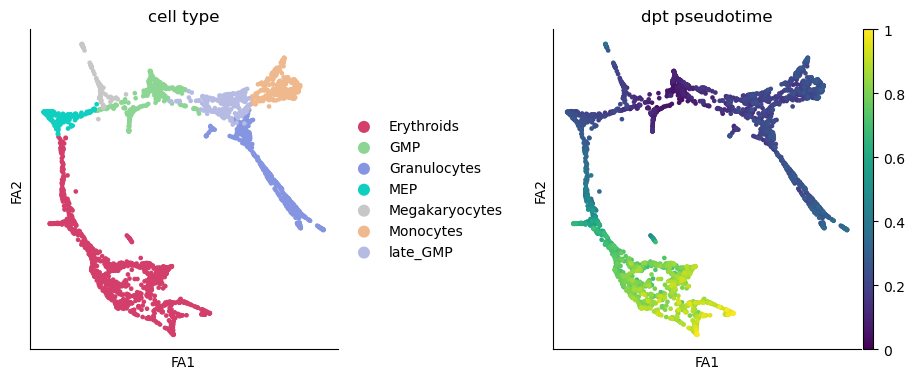

In [6]:
sc.pl.scatter(
    adata,
    basis="draw_graph_fa",
    color=["cell_type", "dpt_pseudotime"],
    use_raw=False,
    layers="MAGIC_imputed_data",
    color_map="viridis",
    right_margin=0.7,
)

In [7]:
genes = ["Gata1", "Spi1", "Cebpa", "Cebpe"]

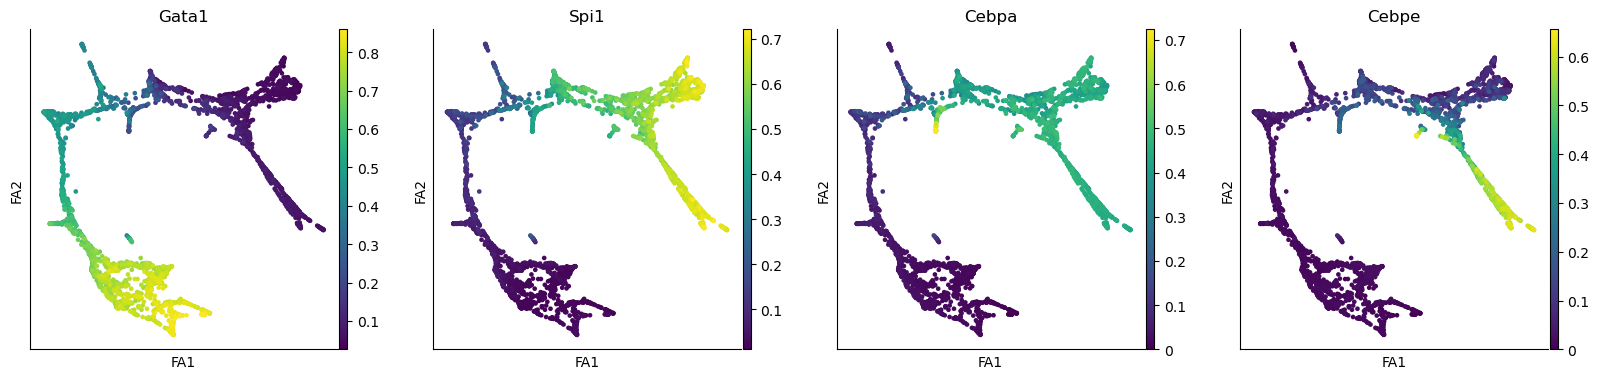

In [8]:
sc.pl.scatter(
    adata,
    basis="draw_graph_fa",
    color=genes,
    use_raw=False,
    layers="MAGIC_imputed_data",
    color_map="viridis",
)

(<Figure size 600x600 with 1 Axes>, <Axes: >)

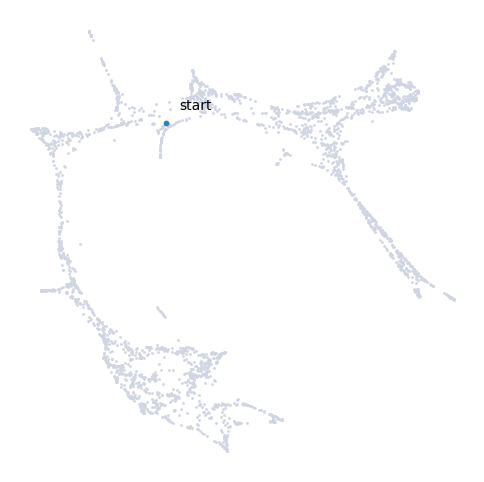

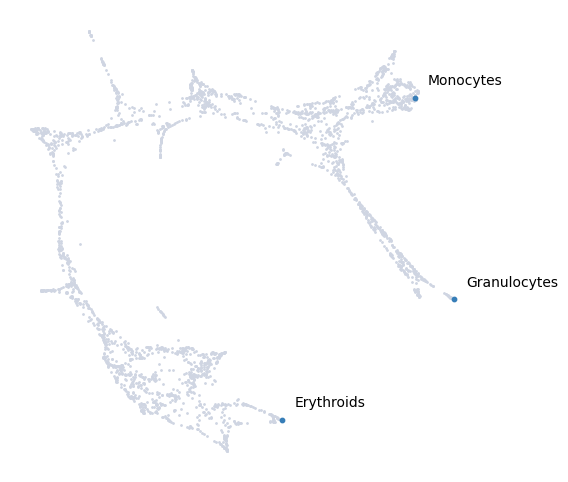

In [9]:
# Define start and end cells
start_cell = adata.obs_names[adata.uns["iroot"][0]]
terminal_states = terminal_states = pd.Series(
    ["Erythroids", "Monocytes", "Granulocytes"],
    index=[
        adata[adata.obs["cell_type"] == "Erythroids"].obs_names[
            adata[adata.obs["cell_type"] == "Erythroids"].obs["dpt_pseudotime"].argmax()
        ],
        adata[adata.obs["cell_type"] == "Monocytes"].obs_names[
            adata[adata.obs["cell_type"] == "Monocytes"].obs["dpt_pseudotime"].argmax()
        ],
        adata[adata.obs["cell_type"] == "Granulocytes"].obs_names[
            adata[adata.obs["cell_type"] == "Granulocytes"]
            .obs["dpt_pseudotime"]
            .argmax()
        ],
    ],
)

palantir.plot.highlight_cells_on_umap(
    adata, {start_cell: "start"}, embedding_basis="X_draw_graph_fa"
)
palantir.plot.highlight_cells_on_umap(
    adata, terminal_states, embedding_basis="X_draw_graph_fa"
)

In [10]:
# Run palantir
pr_res = palantir.core.run_palantir(
    adata, start_cell, num_waypoints=500, terminal_states=terminal_states
)

Sampling and flocking waypoints...
Time for determining waypoints: 0.0009438355763753255 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.06972901821136475 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9999
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


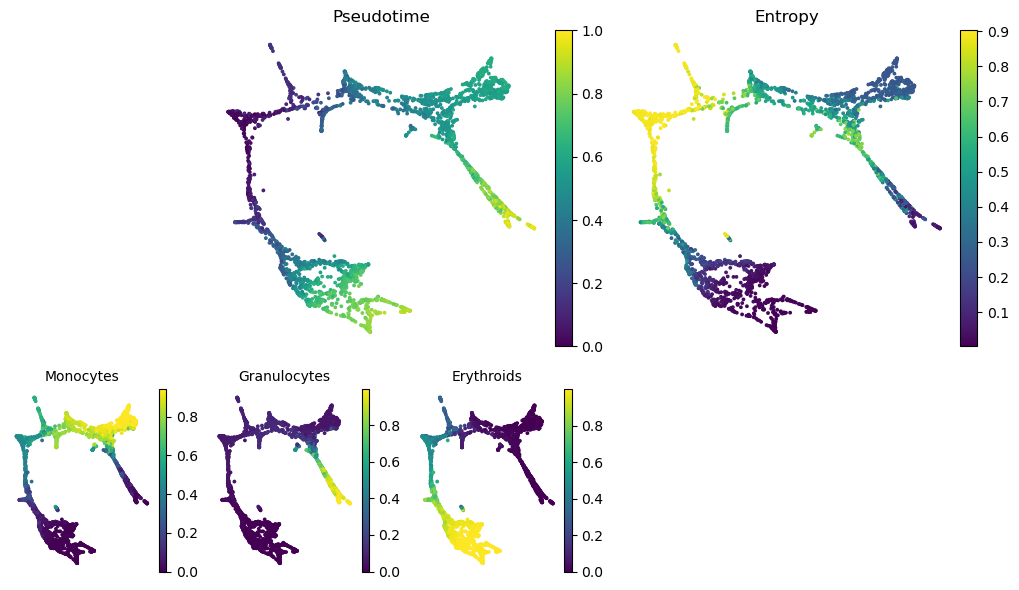

In [11]:
palantir.plot.plot_palantir_results(
    adata, s=3, cmap="viridis", embedding_basis="X_draw_graph_fa"
)
plt.show()

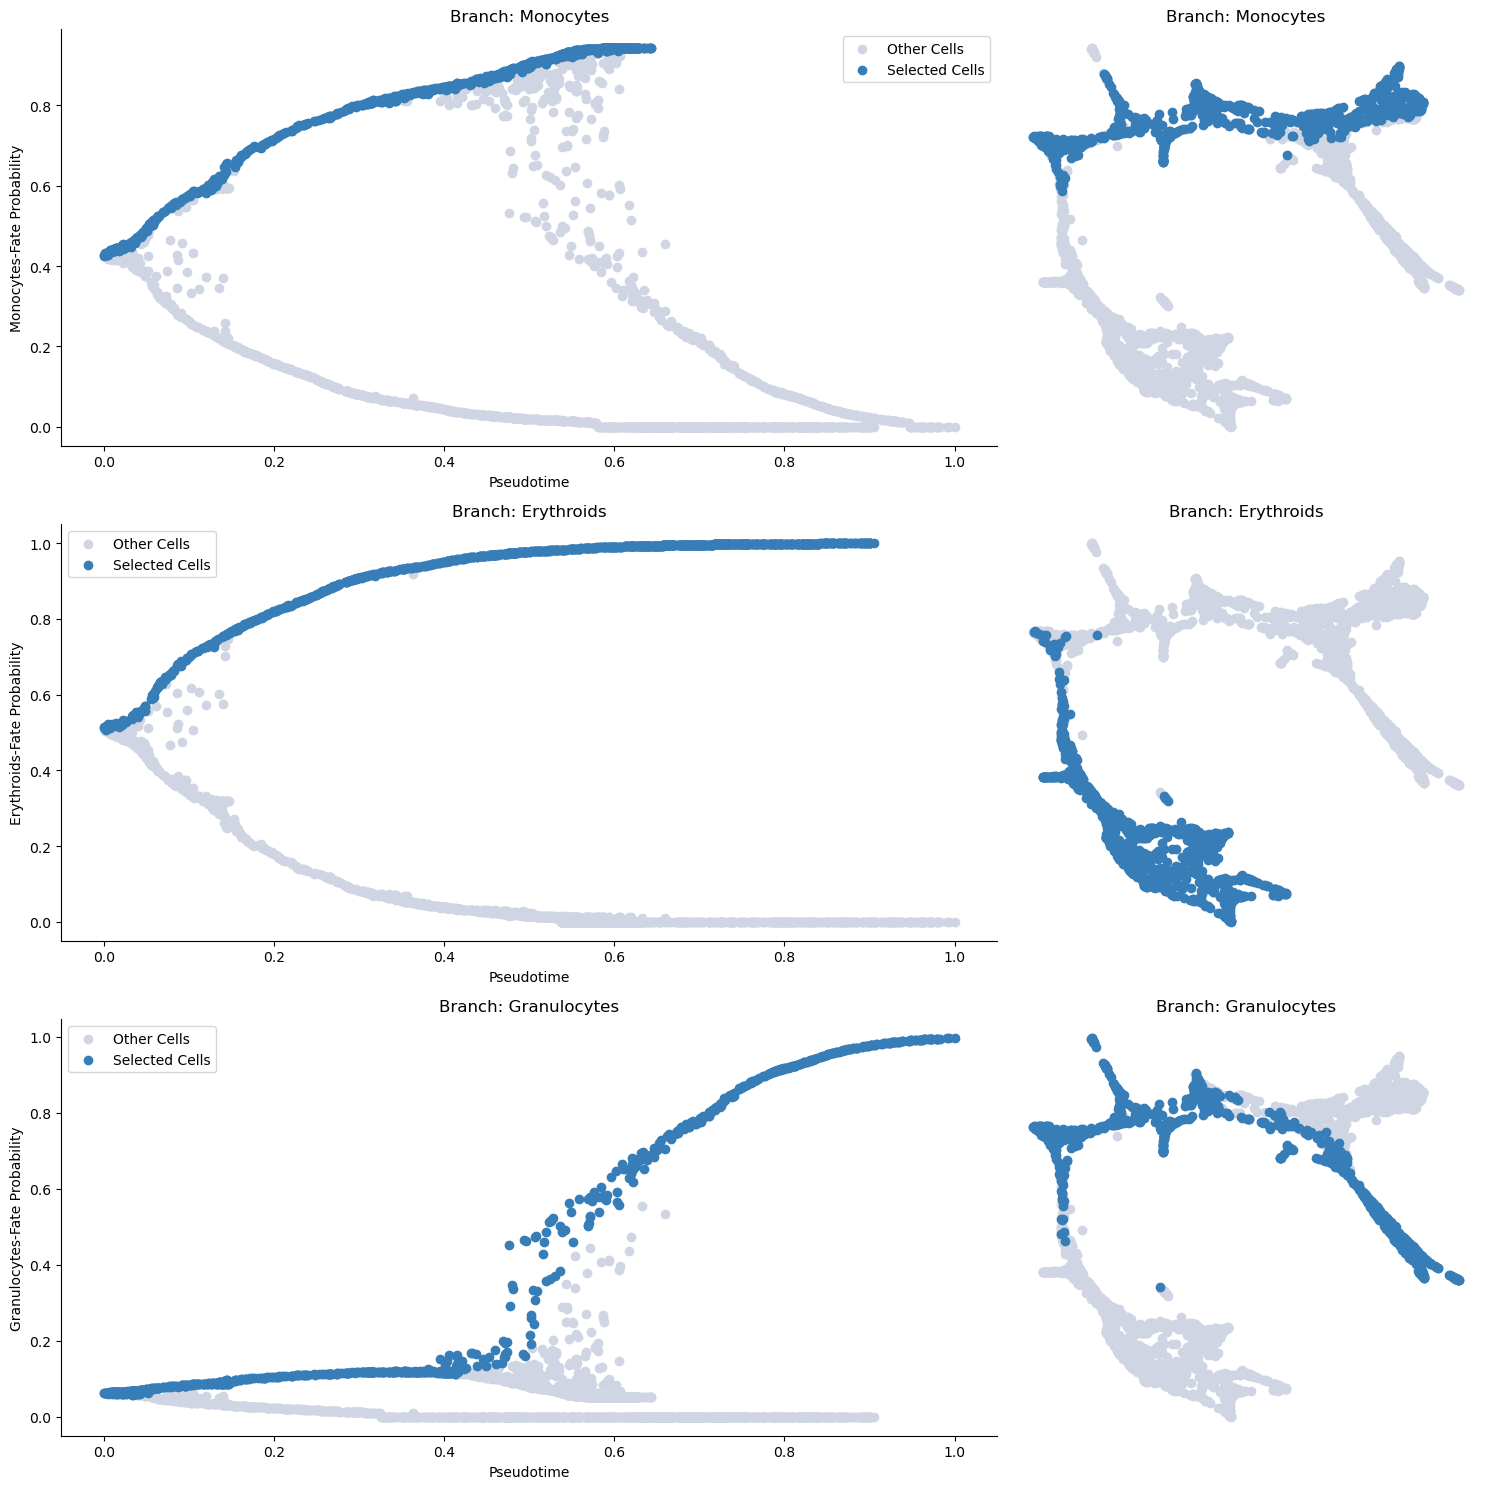

In [12]:
masks = palantir.presults.select_branch_cells(adata, q=0.01, eps=0.01)
palantir.plot.plot_branch_selection(adata, embedding_basis="X_draw_graph_fa")
plt.show()

In [13]:
gene_trends = palantir.presults.compute_gene_trends(
    adata,
    expression_key="MAGIC_imputed_data",
)

/Users/janschleicher/miniconda3/envs/palantir/lib/python3.12/site-packages/palantir/presults.py:265: FutureWarning: Use obs (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`) instead of AnnData.obs_keys, AnnData.obs_keys is deprecated and will be removed in the future.
  if pseudo_time_key not in ad.obs_keys():


Monocytes
[2026-04-08 08:49:00,330] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (976) and rank = 1.0.
[2026-04-08 08:49:00,330] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-04-08 08:49:01,336] [INFO    ] Sigma interpreted as element-wise standard deviation.
Granulocytes
[2026-04-08 08:49:01,578] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (902) and rank = 1.0.
[2026-04-08 08:49:01,579] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-04-08 08:49:01,983] [INFO    ] Sigma interpreted as element-wise standard deviation.
Erythroids
[2026-04-08 08:49:02,103] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (1,077) and rank = 1.0.
[2026-04-08 08:49:02,103] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-04-08 08:49:02,496] [INFO    ] Sigma interpreted as element-wise standard deviation.


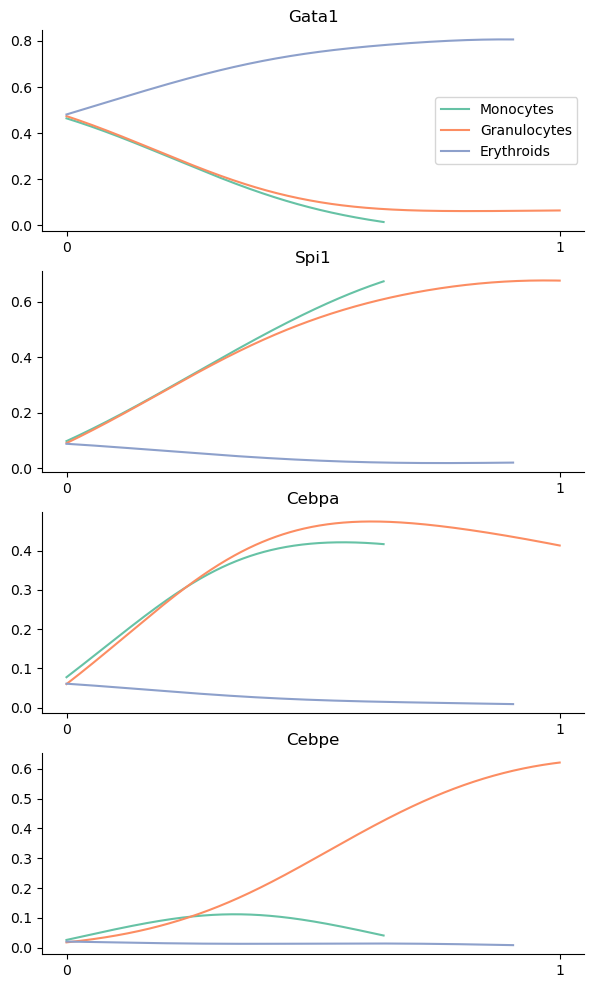

In [14]:
palantir.plot.plot_gene_trends(adata, genes)
plt.show()

In [ ]:
hematopoiesis_genes = [
    "Gata1",
    "Epor",
    "Cebpa",
    "Cebpe",
    "Gfi1",
    "Spi1",
    "Stat3",
    "Gata2",
    "Tal1",
    "Irf8",
    "Fli1",
]
adata.var["hematopoiesis_gene"] = adata.var_names.isin(hematopoiesis_genes)

In [16]:
for gene in hematopoiesis_genes:
    if gene not in adata.var_names:
        print(f"{gene} not found.")

Epor not found.
Tal1 not found.


In [17]:
tflink_df = pd.read_csv("../data/grns/tflink_mm.csv")
display(tflink_df)

,source,target,small_scale
0,Rfx5,H2-Ab1,Yes
1,Rela,Trim63,Yes
2,Creb1,Chgb,Yes
3,Mybl1,Rfx2,Yes
4,Hif1a,Bax,Yes
...,...,...,...
4057577,Smyd3,Slc38a10,No
4057578,Stag2,Rtp4,No
4057579,Sirt6,Ppp1r3e,No
4057580,Nr4a1,Mrpl49,No


In [18]:
# Make input GRN
grn = nx.from_pandas_edgelist(
    tflink_df[
        (tflink_df["source"].isin(hematopoiesis_genes))
        & (tflink_df["target"].isin(hematopoiesis_genes))
        & (tflink_df["small_scale"] == "Yes")
    ],
    source="source",
    target="target",
    create_using=nx.DiGraph,
)
for gene in hematopoiesis_genes:
    if gene not in grn.nodes():
        grn.add_node(gene)

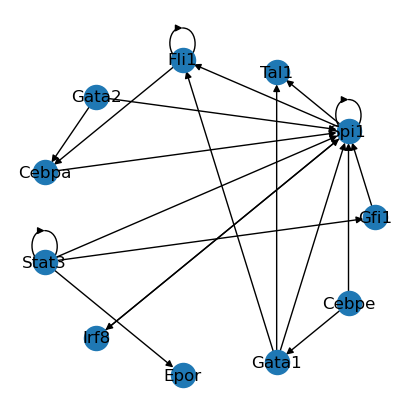

In [19]:
nx.draw_circular(grn, with_labels=True)

In [20]:
adata.layers["imputed"] = csr_matrix(adata.layers["raw_count"].copy())
adata.layers["imputed"] = adata.obsp["connectivities"].dot(adata.layers["imputed"])
adata.layers["imputed_log1p"] = sc.pp.log1p(adata.layers["imputed"].copy())

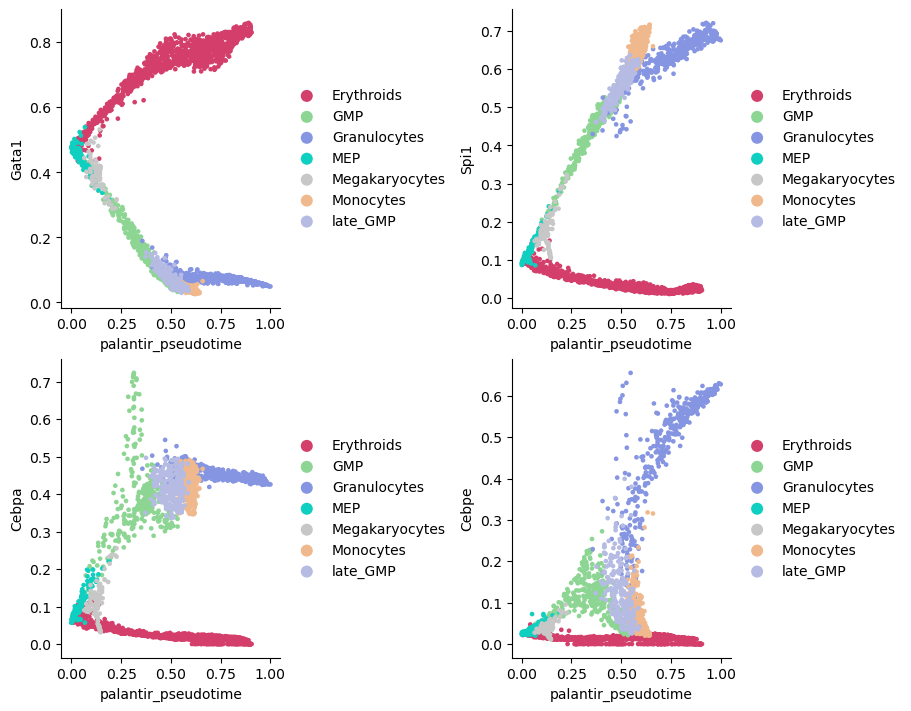

In [21]:
fig, axs = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")

for i, gene in enumerate(genes):
    sc.pl.scatter(
        adata,
        x="palantir_pseudotime",
        y=gene,
        layers="MAGIC_imputed_data",
        ax=axs.flat[i],
        color="cell_type",
        show=False,
        title="",
        use_raw=False,
    )
sns.despine(fig)

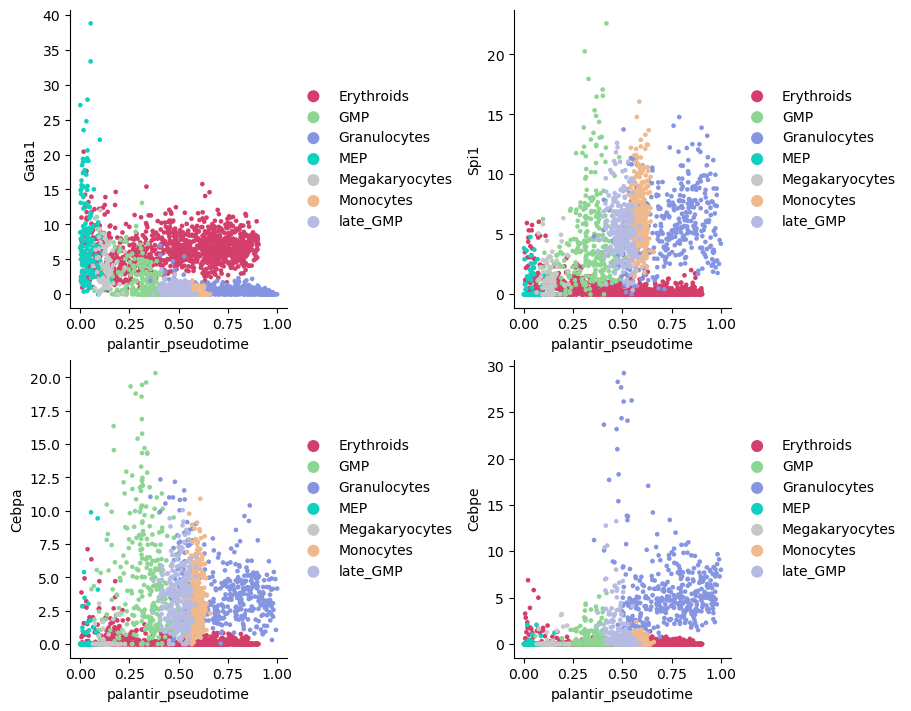

In [22]:
fig, axs = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")

for i, gene in enumerate(genes):
    sc.pl.scatter(
        adata,
        x="palantir_pseudotime",
        y=gene,
        layers="imputed",
        ax=axs.flat[i],
        color="cell_type",
        show=False,
        title="",
        use_raw=False,
    )
sns.despine(fig)

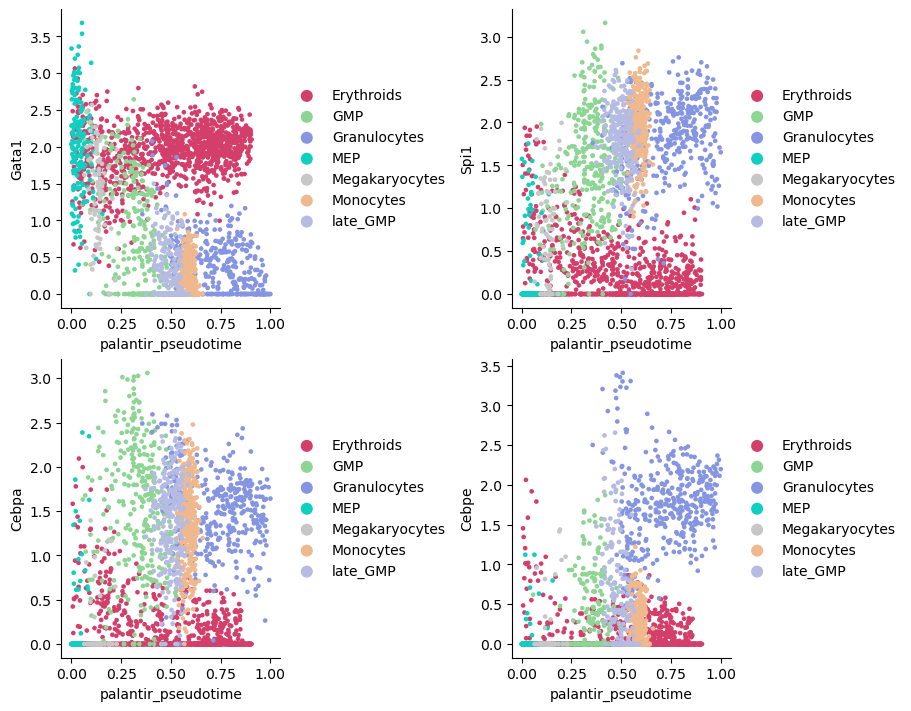

In [23]:
fig, axs = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")

for i, gene in enumerate(genes):
    sc.pl.scatter(
        adata,
        x="palantir_pseudotime",
        y=gene,
        layers="imputed_log1p",
        ax=axs.flat[i],
        color="cell_type",
        show=False,
        title="",
        use_raw=False,
    )
sns.despine(fig)

In [24]:
# Remove monocyte branch (ends earlier than the other two!)
adata_sub = adata[adata.obs["cell_type"] != "Monocytes"]

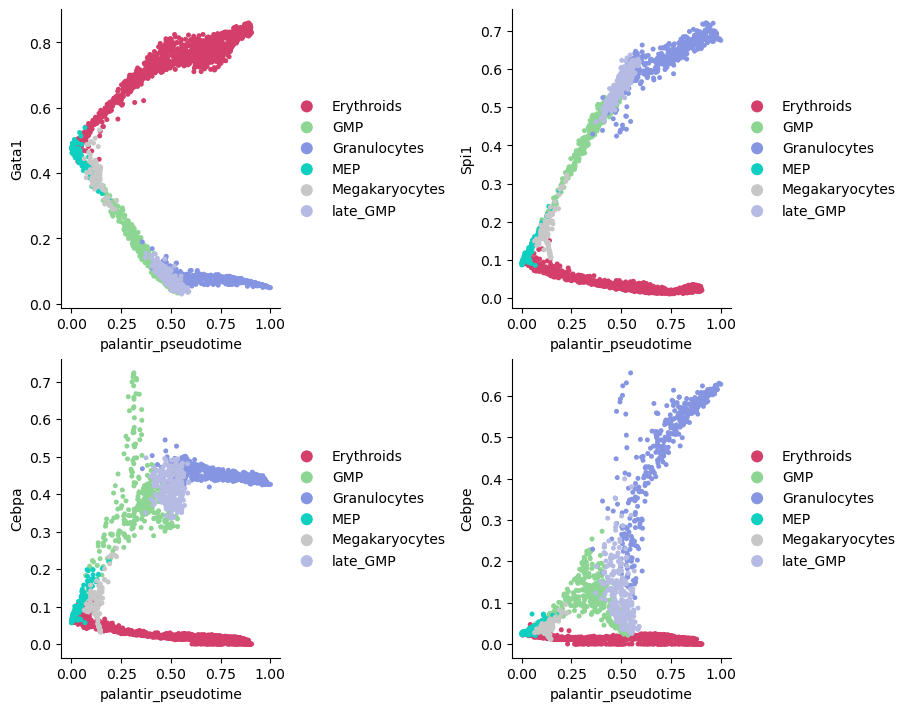

In [25]:
fig, axs = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")

for i, gene in enumerate(genes):
    sc.pl.scatter(
        adata_sub,
        x="palantir_pseudotime",
        y=gene,
        layers="MAGIC_imputed_data",
        ax=axs.flat[i],
        color="cell_type",
        show=False,
        title="",
        use_raw=False,
    )
sns.despine(fig)

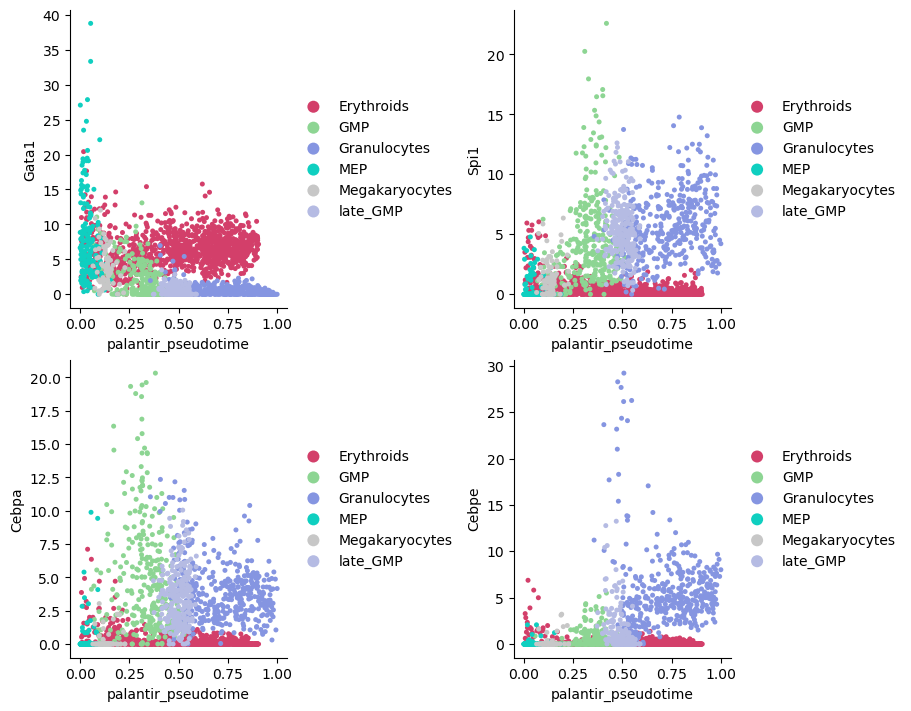

In [26]:
fig, axs = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")

for i, gene in enumerate(genes):
    sc.pl.scatter(
        adata_sub,
        x="palantir_pseudotime",
        y=gene,
        layers="imputed",
        ax=axs.flat[i],
        color="cell_type",
        show=False,
        title="",
        use_raw=False,
    )
sns.despine(fig)

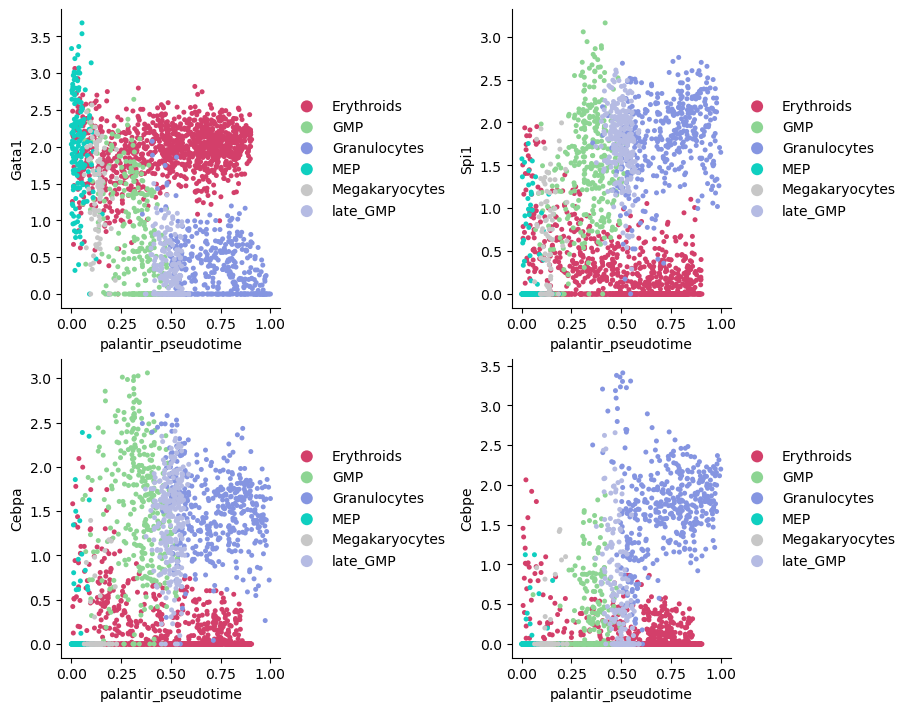

In [27]:
fig, axs = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")

for i, gene in enumerate(genes):
    sc.pl.scatter(
        adata_sub,
        x="palantir_pseudotime",
        y=gene,
        layers="imputed_log1p",
        ax=axs.flat[i],
        color="cell_type",
        show=False,
        title="",
        use_raw=False,
    )
sns.despine(fig)

In [ ]:
adata_sub.write_h5ad("../data/hematopoiesis_processed.h5ad", compression="gzip")